# 06 - Preparación de datos para modelado

**Responsable:** Leonardo Mejía

Genera la caché de secuencias preprocesadas y el split por participante que usan **todos** los modelos.
Correrlo una vez después de `00_setup_datos.ipynb` (tarda ~10 s). También se puede hacer desde la terminal con `python -m src.dataset`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import dataset, features, vocab

sns.set_theme(style="whitegrid")

## 1. Caché de secuencias

Por cada secuencia de la muestra (`src/features.py`):
- se toman manos (21 puntos c/u) y pose (33 puntos), sin rostro, igual que en `02_limpieza_preprocesamiento`;
- cada mano se centra en la muñeca y se escala por la distancia muñeca–MCP medio; la pose se centra en los hombros;
- se agrega una **máscara de detección** por mano (la derecha falta en ~54.5 % de los cuadros);
- se aplica *forward-fill* y lo que queda vacío al inicio va a 0;
- se descartan secuencias con mano en menos del 10 % de los cuadros.

In [2]:
cache = dataset.construir_cache()
largos = np.diff(cache["offsets"])
print("Features por cuadro:", features.NUM_FEATURES)
print("Clases CTC (59 caracteres + blank):", vocab.NUM_CLASSES)

1878 secuencias guardadas, 119 descartadas -> data/processed/secuencias_modelado.npz
Features por cuadro: 227
Clases CTC (59 caracteres + blank): 60


## 2. Split por participante

Se reparten **participantes**, no secuencias, para medir si el modelo generaliza a personas que no vio.
El split queda versionado en `data/split.json`; no lo regeneren para que todos comparen sobre el mismo.

In [3]:
if not dataset.SPLIT_PATH.exists():
    dataset.crear_split(cache["participant_id"])
split = dataset.cargar_split()

filas = []
for particion in ("train", "val", "test"):
    idx = dataset.indices_de(cache, particion, split)
    filas.append({
        "particion": particion,
        "participantes": len(split[particion]),
        "secuencias": len(idx),
        "cuadros_mediana": int(np.median(largos[idx])),
        "cuadros_max": int(largos[idx].max()),
        "chars_mediana": int(np.median([len(f) for f in cache["phrase"][idx]])),
    })
resumen_split = pd.DataFrame(filas)
resumen_split

,particion,participantes,secuencias,cuadros_mediana,cuadros_max,chars_mediana
0,train,64,1315,148,751,17
1,val,14,295,159,541,17
2,test,14,268,142,439,17


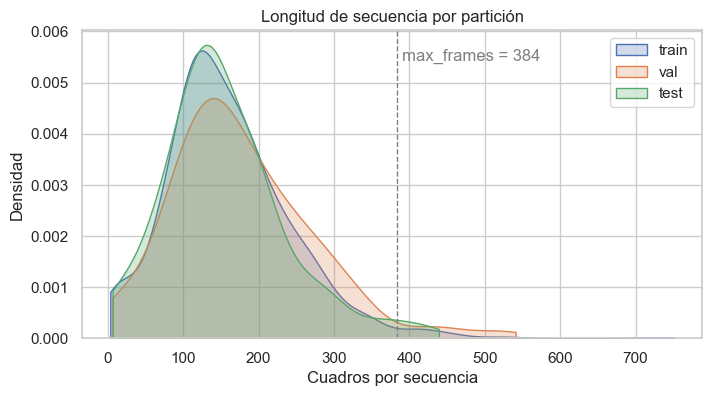

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for particion in ("train", "val", "test"):
    idx = dataset.indices_de(cache, particion, split)
    sns.kdeplot(largos[idx], ax=ax, label=particion, fill=True, alpha=0.25, cut=0)
ax.axvline(384, color="gray", ls="--", lw=1)
ax.text(390, ax.get_ylim()[1] * 0.9, "max_frames = 384", color="gray")
ax.set_xlabel("Cuadros por secuencia")
ax.set_ylabel("Densidad")
ax.set_title("Longitud de secuencia por partición")
ax.legend()
fig.savefig("../reports/figures/06_longitud_por_particion.png", dpi=150, bbox_inches="tight")
plt.show()

Las tres particiones tienen distribuciones de longitud parecidas, así que la diferencia entre val y test no debería venir de la duración.
Las secuencias de más de 384 cuadros se submuestrean de forma equiespaciada al cargarlas (`max_frames`).

In [5]:
print("Secuencias por encima de 384 cuadros:", int((largos > 384).sum()), f"({100 * (largos > 384).mean():.1f} %)")

Secuencias por encima de 384 cuadros: 38 (2.0 %)


## 3. Cómo usarlo en su notebook

```python
from src import dataset, train

loaders = dataset.crear_dataloaders(batch_size=32, max_frames=384)   # transform=augment... para Cindy
x, x_len, y, y_len = next(iter(loaders["train"]))                    # x: (B, T, 227)
```

Cada modelo vive en `src/models/<nombre>.py` con la clase y `construir(**hiperparametros)`, y su `forward(x, x_len)`
devuelve `(log_probs (B, T', vocab.NUM_CLASSES), out_len)` con `log_softmax` aplicado. Si el modelo reduce el tiempo
(stride), `out_len` debe reflejarlo.

```python
from src.models import cnn_bigru

hp = {"hidden": 128, "stride": 2}
model = cnn_bigru.construir(**hp)
resultado = train.fit(model, loaders["train"], loaders["val"], {"epochs": 40, "lr": 1e-3})
train.guardar_resultados("cnn_bigru", model, hp, resultado, loaders)   # models/cnn_bigru.pt + reports/metrics/cnn_bigru.json
```

In [6]:
loaders = dataset.crear_dataloaders(batch_size=8)
x, x_len, y, y_len = next(iter(loaders["train"]))
print("x:", tuple(x.shape), "| x_len:", x_len.tolist())
print("y:", tuple(y.shape), "| ejemplo:", vocab.decode(y[0][: y_len[0]].tolist()))

x: (8, 253, 227) | x_len: [125, 234, 181, 180, 121, 78, 183, 253]
y: (8, 29) | ejemplo: 332-407-4241
